# Controlled MolMIM with Custom Oracle - QSAR 01

In [4]:
!pip install cma matplotlib numpy pandas rdkit

In [5]:
!pip install msal

In [6]:
import cma
import json
import matplotlib.pyplot as plt
import numpy as np
import requests
from IPython.display import display, clear_output
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.QED import qed
from rdkit.Chem.Crippen import MolLogP
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.DataStructs import TanimotoSimilarity
from rdkit import RDLogger                                                                                                                                                               
RDLogger.DisableLog('rdApp.*')

### Define the NIM host
To get started, we'll define our NIM host and the NIM endpoints we'll use in the following cells.

 - `/sampling` - Perform random sampling around a seed SMILES to define a starting population
 - `/hidden` - Generate the hidden state encoding for a set of input SMILES
 - `/decode` - Decode hidden state encodings to return a set of SMILES

In [7]:
!docker ps -a
# In case you want to stop the container -> !docker stop molmim

CONTAINER ID   IMAGE                                                       COMMAND                  CREATED         STATUS              PORTS                                                           NAMES
ec4e065a6128   841162696343.dkr.ecr.us-east-1.amazonaws.com/molmim:1.0.0   "/opt/nvidia/nvidia_…"   2 minutes ago   Up About a minute   6006/tcp, 8888/tcp, 0.0.0.0:8080->8000/tcp, :::8080->8000/tcp   molmim-prod


In [8]:
nim_host="127.0.0.1"
port="8080"
sampling_url=f"http://{nim_host}:{port}/sampling"
hidden_url=f"http://{nim_host}:{port}/hidden"
decode_url=f"http://{nim_host}:{port}/decode"

Let's run a health check on our NIM:

In [9]:
!curl {nim_host}:{port}/v1/health/ready

curl: (56) Recv failure: Connection reset by peer


# define seeds

In [7]:
# first Bayer Seed
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

In [8]:
# second seed
m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m2_name = "BCS-CE65417"

# Bayer Custom Scoring function

In [9]:
from by_scorer import create_scorer

# Using both QSAR models with different weights
scorer = create_scorer(
    use_qsar_hsec=False,
    use_qsar_sip=False,
    use_qed = True,
    use_similarity=True,
)

# Score molecules and access both QSAR predictions
#results = scorer.score(molecules, reference_smiles=m1)
#print(f"QSAR-SIP: {results.qsar_sip_scores}")
#print(f"QSAR-HSEC: {results.qsar_hsec_scores}")

# First an example using random sampling around the initial seed

In [10]:
# Define a starting array of seed SMIs

mol = Chem.MolFromSmiles(m1)
imatinib_logp = MolLogP(mol)

starting_smiles = [
    m1,
    m1,
    m1,
    m1,
    m1,
]

generated_smiles = []
tanimoto_scores = []
logp_scores = []
sampling_summary = {}

# Create the request data
for smi in starting_smiles:
    data = {
        'sequences': [smi],
        'beam_size': 3,
        'num_molecules': 10, # reduce if more starting molecules are used
        'scaled_radius': 1.0,
    }

    # Send the request and get the response
    headers = {'Content-Type': 'application/json'}
    response = requests.post(sampling_url, headers=headers, json=data)
    
    # Parse the response as JSON
    response_json = json.loads(response.text)
    
    # Extract the generated SMILES strings
    generated_molecules = response_json['generated'][0]
    
    # Filter out invalid SMILES strings
    valid_smiles = [m for m in generated_molecules if Chem.MolFromSmiles(m) is not None]
    generated_smiles.extend(valid_smiles)

results = scorer.score(generated_smiles, reference_smiles=m1)

# Sampling summary - valid smiles count, average Tanimoto and QED scores
sampling_summary['valid_smiles'] = len(generated_smiles)
sampling_summary['Score_Metric'] = np.mean(results.qed_scores) ## CHANGE IF METRIC CHANGES
sampling_summary['Similarity'] = np.mean(results.similarity_scores)


print(f"Valid SMILES = {sampling_summary['valid_smiles']}, mean score = {sampling_summary['Score_Metric']}, mean similarity {sampling_summary['Similarity']}")


#~now scoring~#
#~Done scoring~#
Valid SMILES = 50, mean score = 0.7489107359645683, mean similarity 0.2511285703369036


# Plot the scores 
of the randomly sampled candidates in our search space.

In [11]:
#seed_score 
# = test_qsar_prediction(m1, "https://chemprop.cropkey-np.ag/activity/ica/invocations") #_hsec
seed_score = qed(Chem.MolFromSmiles(m1))
print(seed_score)

0.8201128477882069


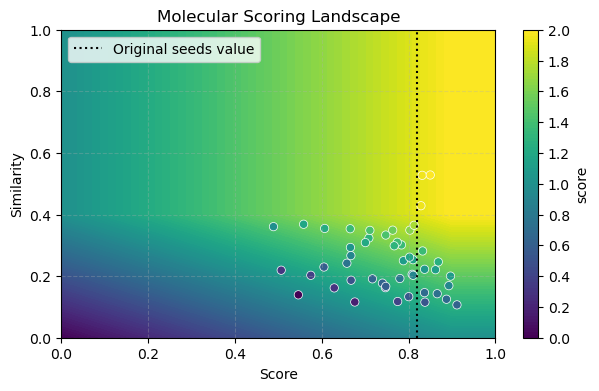

In [12]:
# get values of molecules from scorer
x_scores = results.qed_scores   ## CHANGE IF METRIC CHANGES
y_scores = results.similarity_scores  

# set color for scattter 
color = -1*results.combined_scores

# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
score_background = -1*scorer.score_from_properties(similarity_values=Ygrid, qed_values=Xgrid) ## CHANGE IF METRIC CHANGES

# Plot everything
plt.figure(figsize=(7, 4))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, score_background, levels=100, cmap='viridis',vmin=0, vmax=2.0)  # Assuming weights sum to 2.0
#plt.colorbar(contour, label='Combined Score')
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seeds value")

# Plot normalized data points
plt.scatter(x_scores, y_scores, c=color, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Score") 
plt.ylabel("Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
#plt.xlim(0, 1)
#plt.ylim(0, 1)



## Controlled Generation with CMA-ES and the custom oracle

### Generate hidden state encoding for the imatinib seed to initialize CMA-ES

To start the CMA-ES optimization process, we first seed the optimizer with the hidden state encoding for our imatinib seed molecule using the `/hidden` endpoint.

In [13]:
# First calculate a hidden state representation of our seed, imatinib.
headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
data = {
    "sequences": [m1],
}

# Get the response from the server
response = requests.post(hidden_url, headers=headers, json=data)
imatinib_hidden = np.squeeze(np.array(response.json()["hiddens"]))

# We can use this seed hidden state as a starting point for our CMA-ES optimizer
popsize = sampling_summary['valid_smiles']
sigma=1.0

# Initialize with zeros or the hidden state encoding for imatinib
#optimizer = cma.CMAEvolutionStrategy(np.zeros(imatinib_hidden.size, dtype=np.float32), sigma, {'popsize': popsize})
optimizer = cma.CMAEvolutionStrategy(imatinib_hidden, sigma, {'popsize': popsize})

(25_w,50)-aCMA-ES (mu_w=14.0,w_1=14%) in dimension 512 (seed=878347, Wed Mar 12 18:19:47 2025)


Now that we've initialized the CMA-ES optimizer, we can generate and decode an initial set of trial encodings using the `/decode` endpoint.

In [14]:
# Generate and decode a set of initial trial encodings with CMA-ESecode trial encodings

trial_encodings=optimizer.ask(popsize)

headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
hiddens_json = {"hiddens":hiddens_array.tolist(),
                "mask": [[True] for i in range(hiddens_array.shape[0])]}


response = requests.post(decode_url, headers=headers, json=hiddens_json)
molecules = list(dict.fromkeys(response.json()['generated']))

We can then calculate the scores for this trial population and plot the results in our search space.

In [15]:
# score current draw
results = scorer.score(molecules, reference_smiles=m1)

# Sampling summary
print(len(molecules))

#~now scoring~#
#~Done scoring~#
49


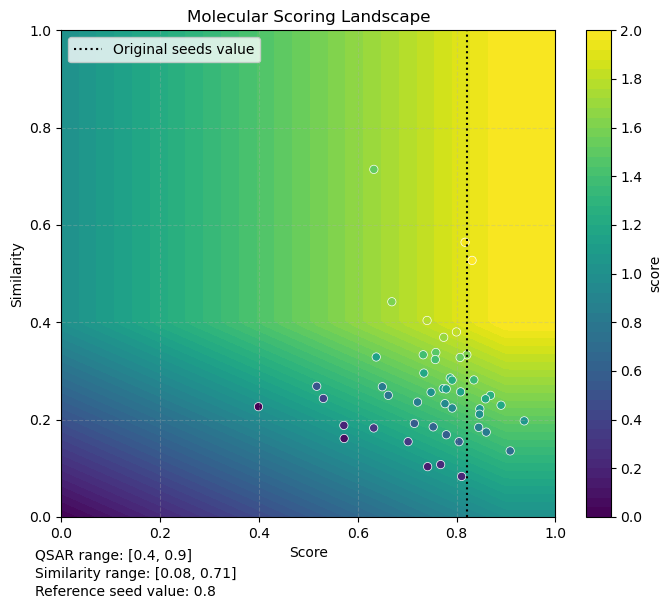

In [19]:
# set values for plot
x_scores = results.qed_scores   ## CHANGE IF METRIC CHANGES
y_scores = results.similarity_scores

# set color for scattter 
color = -1*results.combined_scores

# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
score_background = -1*scorer.score_from_properties(similarity_values=Ygrid, qed_values=Xgrid) ## CHANGE IF METRIC CHANGES

# Plot everything
plt.figure(figsize=(7, 6))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, score_background, levels=50, cmap='viridis',vmin=0, vmax=2.0)  # Assuming weights sum to 2.0
#plt.colorbar(contour, label='Combined Score')
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seeds value")

# Plot normalized data points
plt.scatter(x_scores, y_scores, c=color, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Score")
plt.ylabel("Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)

# Add annotations showing ranges and reference value
plt.annotate(f"QSAR range: [{min(x_scores):.1f}, {max(x_scores):.1f}]",
             xy=(0.05, 0.07), xycoords='figure fraction')
plt.annotate(f"Reference seed value: {seed_score:.1f}",
             xy=(0.05, 0.01), xycoords='figure fraction')
plt.annotate(f"Similarity range: [{min(y_scores):.2f}, {max(y_scores):.2f}]",
             xy=(0.05, 0.04), xycoords='figure fraction')

plt.tight_layout()
plt.show()

### Iterative optimization with CMA-ES and the custom oracle function
Now that we have our starting population, we can iteratively optimize using the CMA-ES strategy:

1. Generate a new set of trial encodings
2. Decode and calculate scores
3. Generate a new set of hidden state representations for valid trial candidates
4. Update the CMA-ES optimizer with the current combination of scores and hidden state representations

Note that through the CMA-ES optimization loop, we will occasionally encounter invalid SMILES depending on the search parameters.  We will stop the CMA-ES optimization loop if we have reduced our starting population by half.

In [20]:
popsize

50

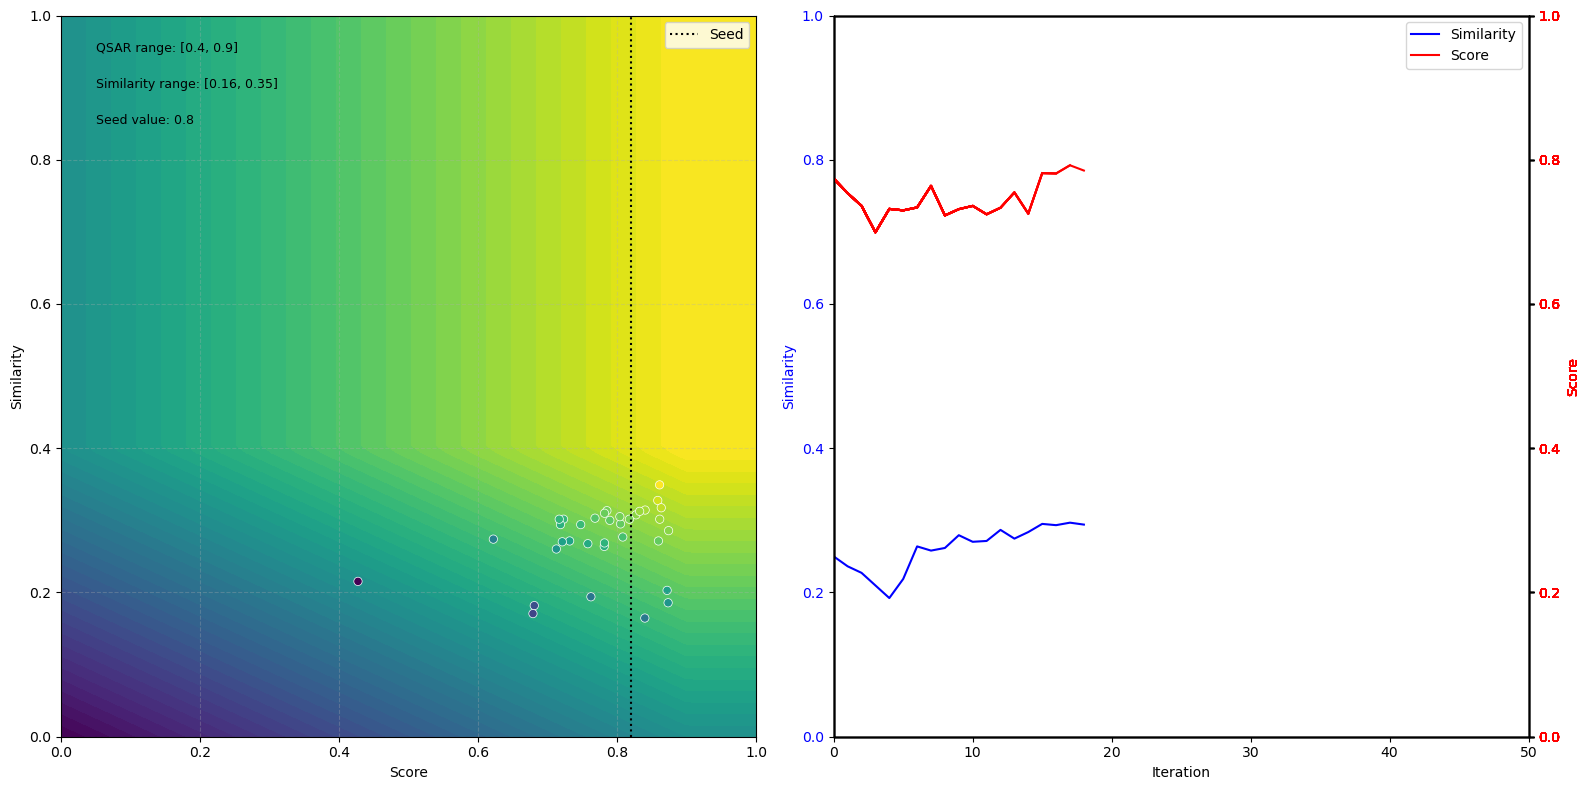

<Figure size 640x480 with 0 Axes>

#~now scoring~#
#~Done scoring~#
Stopping at minimum population size 22


In [21]:
%matplotlib inline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
# Initialize tracking lists
med_scores = [np.median(np.array(results.qed_scores))]
med_sims = [np.median(np.array(results.similarity_scores))]
# set parameters for optim
minpopsize = popsize/2
n_steps = popsize # change if needed

for i in range(n_steps):
    # Ask for trial encodings
    trial_encodings = optimizer.ask(popsize)
    
    # Decode to molecules
    hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
    hiddens_json = {"hiddens": hiddens_array.tolist(), "mask": [[True] for _ in range(hiddens_array.shape[0])]}
    response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
    
    # Process valid molecules
    molecules = list(dict.fromkeys(response.json()['generated']))
    valid_smiles = [m for m in molecules if Chem.MolFromSmiles(m) is not None]
    
    # Get encodings for valid SMILES
    data = {"sequences": valid_smiles}
    response = requests.post(hidden_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=data)
    hiddens_array = np.squeeze(np.array(response.json()["hiddens"]))
    
    # Score molecules
    results = scorer.score(valid_smiles, reference_smiles=m1)
    popsize = len(results.combined_scores)
    
    # Check population size
    if popsize <= minpopsize:
        print(f"Stopping at minimum population size {popsize}")
        break
        
    # Update optimizer
    optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
    
    # Extract scores
    x_scores = results.qed_scores
    y_scores = results.similarity_scores
    color = -1*results.combined_scores
    # Clear plots
    ax1.clear()
    ax2.clear()
    clear_output(wait=True)
    
    # Create normalized version of the data for consistent plotting
    #x_norm = (np.array(x_scores) - min(x_scores)) / (max(x_scores) - min(x_scores)) if max(x_scores) > min(x_scores) else x_scores
    #y_norm = (np.array(y_scores) - min(y_scores)) / (max(y_scores) - min(y_scores)) if max(y_scores) > min(y_scores) else y_scores
    
    # Plot 1: Molecular landscape with improved visualization
    # Create grid for the background
    deltas = np.linspace(0, 1, 100)
    Xgrid, Ygrid = np.meshgrid(deltas, deltas)
    
    # Calculate score background
    score_background = -1 * scorer.score_from_properties(similarity_values=Ygrid, qed_values=Xgrid)
    
    # Plot contour with fixed range
    ax1.contourf(Xgrid, Ygrid, score_background, levels=50, cmap='viridis', vmin=0, vmax=2.0)
    
    # Calculate normalized seed score
    #seed_norm = (seed_score - min(x_scores)) / (max(x_scores) - min(x_scores)) if max(x_scores) > min(x_scores) else seed_score
    
    # Plot reference line for seed value
    ax1.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Seed")
    
    # Plot data points (use normalized coordinates for consistent plotting)
    ax1.scatter(x_scores, y_scores, c=color, edgecolor='white', linewidths=0.5, cmap='viridis')
    
    # Set labels and axes
    ax1.set_xlabel("Score")
    ax1.set_ylabel("Similarity")
    ax1.set_xlim(0, 1)  # Normalized range
    ax1.set_ylim(0, 1)  # Normalized range
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.legend()
    
    # Add annotations with actual value ranges
    ax1.annotate(f"QSAR range: [{min(x_scores):.1f}, {max(x_scores):.1f}]",
                xy=(0.05, 0.95), xycoords='axes fraction', fontsize=9)
    ax1.annotate(f"Similarity range: [{min(y_scores):.2f}, {max(y_scores):.2f}]",
                xy=(0.05, 0.90), xycoords='axes fraction', fontsize=9)
    ax1.annotate(f"Seed value: {seed_score:.1f}",
                xy=(0.05, 0.85), xycoords='axes fraction', fontsize=9)
    
    # Plot 2: Tracking with dual y-axis (unchanged)
    med_scores.append(np.median(x_scores))
    med_sims.append(np.median(y_scores))
    # Create secondary axis for QSAR scores
    ax2_qsar = ax2.twinx()
    # Plot similarity on primary axis
    line_sim = ax2.plot(med_sims, color='blue', label='Similarity')
    ax2.set_ylabel("Similarity", color='blue')
    ax2.tick_params(axis='y', labelcolor='blue')
    ax2.set_ylim(0, 1)
    # Plot QSAR on secondary axis with fixed range
    line_qsar = ax2_qsar.plot(med_scores, color='red', label='Score')
    ax2_qsar.set_ylabel("Score", color='red')
    ax2_qsar.tick_params(axis='y', labelcolor='red')
    #ax2_qsar.set_ylim(-40, 1200)  # Fixed axis range for QSAR score
    ax2_qsar.set_ylim(0, 1)
    # Combine legends
    lines = line_sim + line_qsar
    labels = [l.get_label() for l in lines]
    ax2.legend(lines, labels)
    ax2.set_xlabel("Iteration")
    ax2.set_xlim(0, n_steps)
    
    # Display figure and update
    plt.tight_layout()
    display(fig)
    plt.pause(0.1)  # Short pause to allow display to update

## Viewing the resulting optimized molecules.

In [22]:
len(valid_smiles)

22

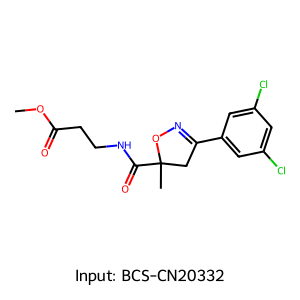

In [23]:
input_mol = Chem.MolFromSmiles(m1)

Draw.MolToImage(input_mol, legend=str(f"Input: {m1_name}" ), subImgSize=(350,360))

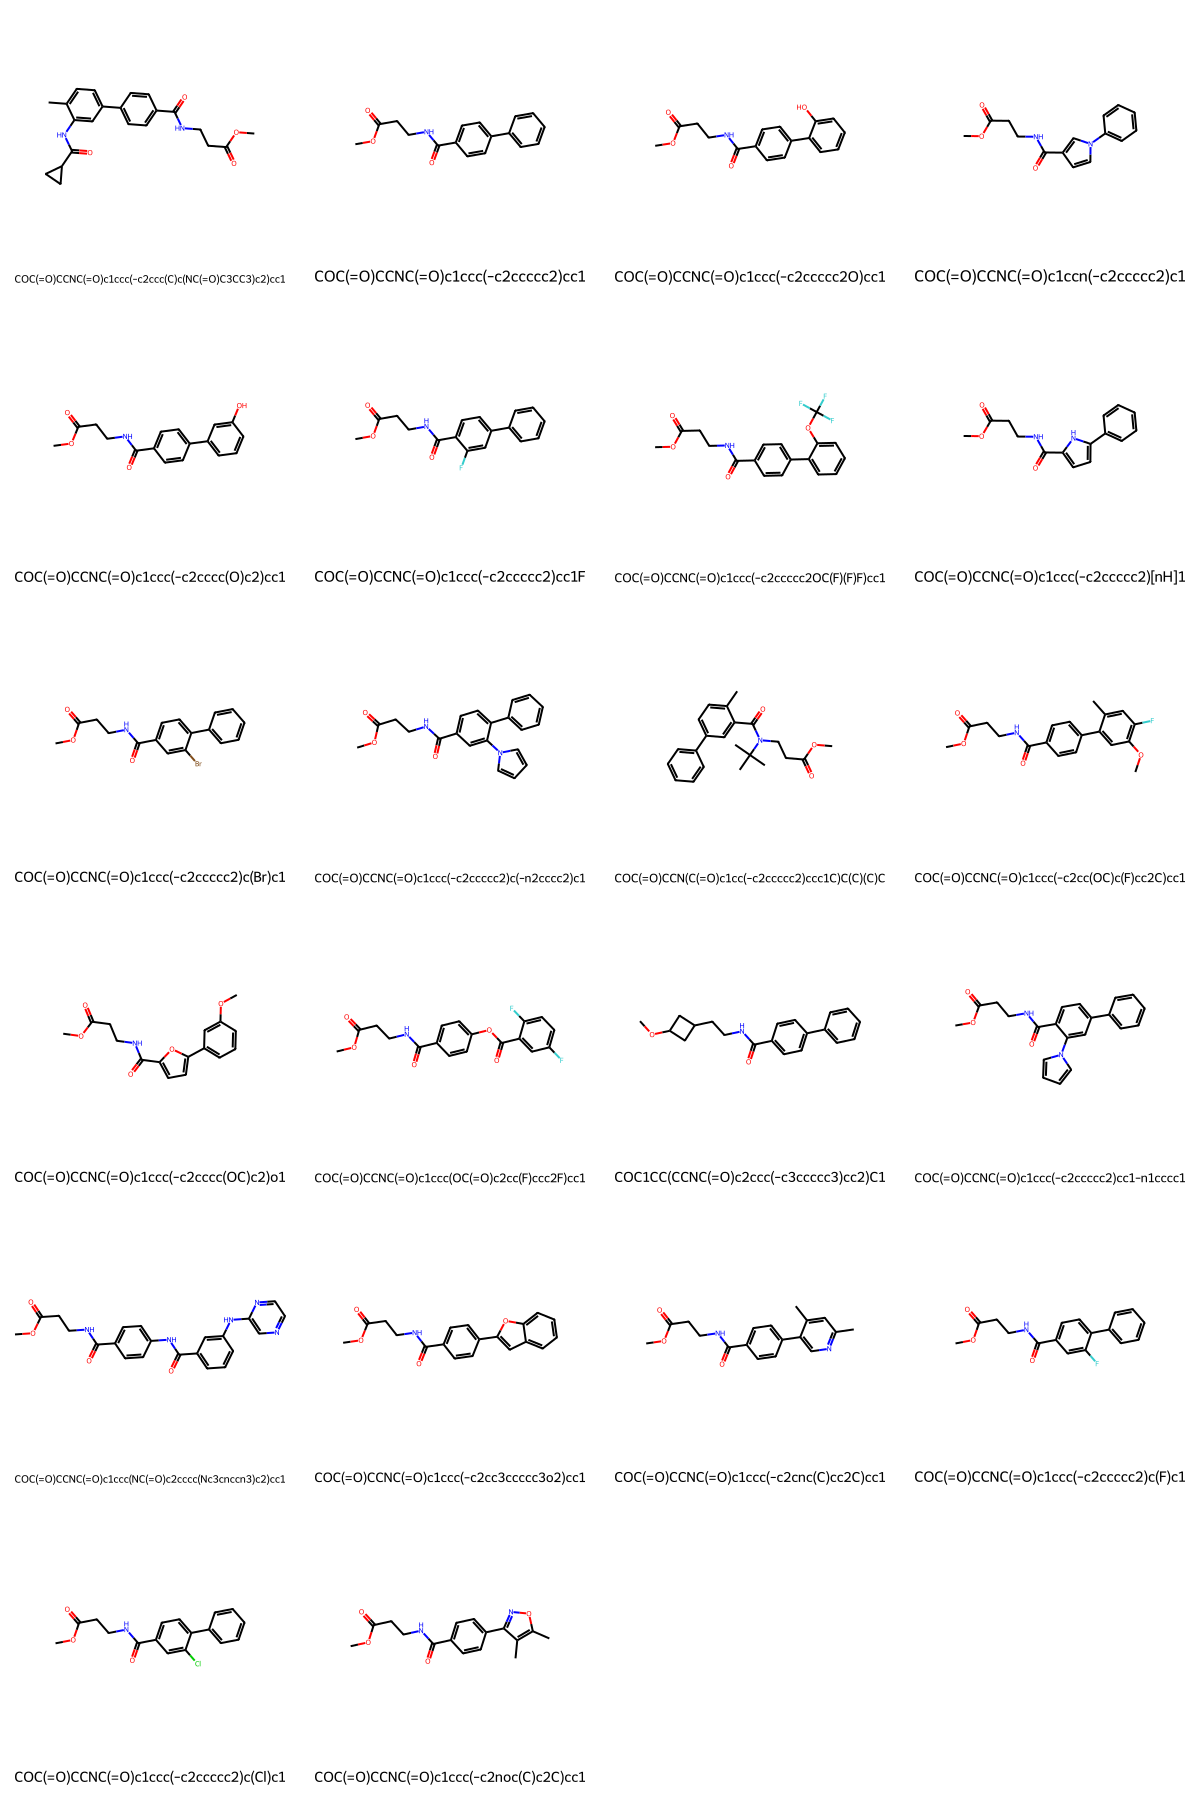

In [24]:
Draw.MolsToGridImage([Chem.MolFromSmiles(smile, sanitize=False) for smile in valid_smiles[:33]],
                     legends=molecules, molsPerRow=4, subImgSize=(300, 300))

In [25]:
import pandas as pd
df = pd.DataFrame({"valid_smiles": valid_smiles })

In [26]:
import helper
df['LogP'] = df['valid_smiles'].apply(helper.calculate_logp)
df['QED'] = df['valid_smiles'].apply(helper.calculate_qed)

In [29]:
df.sort_values(["QED"], inplace=True, ascending=False)
df.head(10)

,valid_smiles,LogP,QED
14,COC1CC(CCNC(=O)c2ccc(-c3ccccc3)cc2)C1,3.89850,0.878649
19,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)c(F)c1,2.78560,0.864013
5,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)cc1F,2.78560,0.864013
18,COC(=O)CCNC(=O)c1ccc(-c2cnc(C)cc2C)cc1,2.65834,0.861891
20,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)c(Cl)c1,3.29990,0.860836
1,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)cc1,2.64650,0.858237
21,COC(=O)CCNC(=O)c1ccc(-c2noc(C)c2C)cc1,2.25134,0.856677
3,COC(=O)CCNC(=O)c1ccn(-c2ccccc2)c1,1.77020,0.843813
2,COC(=O)CCNC(=O)c1ccc(-c2ccccc2O)cc1,2.35210,0.831011
4,COC(=O)CCNC(=O)c1ccc(-c2cccc(O)c2)cc1,2.35210,0.831011


In [26]:
#df.to_csv('../../data/interim/molmim/guided/XXXXXX.csv', index=False, sep=';', header=True) 
#../../data/interim/molmmim_BCS-CN20332_LogP_sim03_100p_100m
#../../data/interim/XXX.csv

## Second Seed